# Paper figure: interaction traces as embedding trajectories

Five RICO interaction traces are drawn as trajectories over a gray UMAP background. Trace-local keys are never treated as embedding IDs: every screen is resolved through `trace_layout_index.csv`, and `gestures.json` insertion order defines the sequence. The quantitative panel compares consecutive-screen cosine distance with random-pair distance in the original embedding space.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from paper_embedding_analysis import (DEFAULT_EMBEDDINGS_DIR, available_embedding_ids, deterministic_sample, fit_umap, load_embeddings, load_trace_sequences, output_dir)

sns.set_theme(context="paper", style="whitegrid", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 300})

C:\Users\Jonathan\Dev\screen2vec-revisited\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
RANDOM_STATE = 42
N_TRACES_TO_PLOT = 5
MIN_PLOT_LENGTH = 5
MAX_PLOT_LENGTH = 20
BACKGROUND_SCREENS = 8_000
MAX_TRANSITIONS = 5_000
OUTPUT_DIR = output_dir("paper_umap_interaction_traces")

In [3]:
available = available_embedding_ids(DEFAULT_EMBEDDINGS_DIR)
sequences = load_trace_sequences(available, min_length=3)
eligible = [row for row in sequences if MIN_PLOT_LENGTH <= len(row["layout_ids"]) <= MAX_PLOT_LENGTH]
rng = np.random.default_rng(RANDOM_STATE)
order = rng.permutation(len(eligible))
plot_traces, used_apps = [], set()
for index in order:
    row = eligible[index]
    if row["app"] not in used_apps:
        plot_traces.append(row)
        used_apps.add(row["app"])
    if len(plot_traces) == N_TRACES_TO_PLOT:
        break
if len(plot_traces) < N_TRACES_TO_PLOT:
    raise ValueError("Not enough eligible traces from distinct apps")
all_transitions = [(a, b) for row in sequences for a, b in zip(row["layout_ids"][:-1], row["layout_ids"][1:])]
if len(all_transitions) > MAX_TRANSITIONS:
    chosen = rng.choice(len(all_transitions), size=MAX_TRANSITIONS, replace=False)
    transitions = [all_transitions[i] for i in chosen]
else:
    transitions = all_transitions
transition_ids = {screen_id for pair in transitions for screen_id in pair}
background_ids = set(deterministic_sample(available, BACKGROUND_SCREENS, RANDOM_STATE))
trajectory_ids = {screen_id for row in plot_traces for screen_id in row["layout_ids"]}
analysis_ids = background_ids | transition_ids | trajectory_ids
ids, X = load_embeddings(analysis_ids, DEFAULT_EMBEDDINGS_DIR, description="Loading trace analysis screens")
id_to_row = {screen_id: i for i, screen_id in enumerate(ids)}
coords, pca = fit_umap(X, random_state=RANDOM_STATE)
coord_by_id = dict(zip(ids, coords))
print(f"{len(sequences):,} usable traces; {len(transitions):,} sampled transitions; UMAP fit on {len(ids):,} screens.")

Loading trace analysis screens: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16479/16479 [00:13<00:00, 1263.16it/s]


7,164 usable traces; 5,000 sampled transitions; UMAP fit on 16,479 screens.


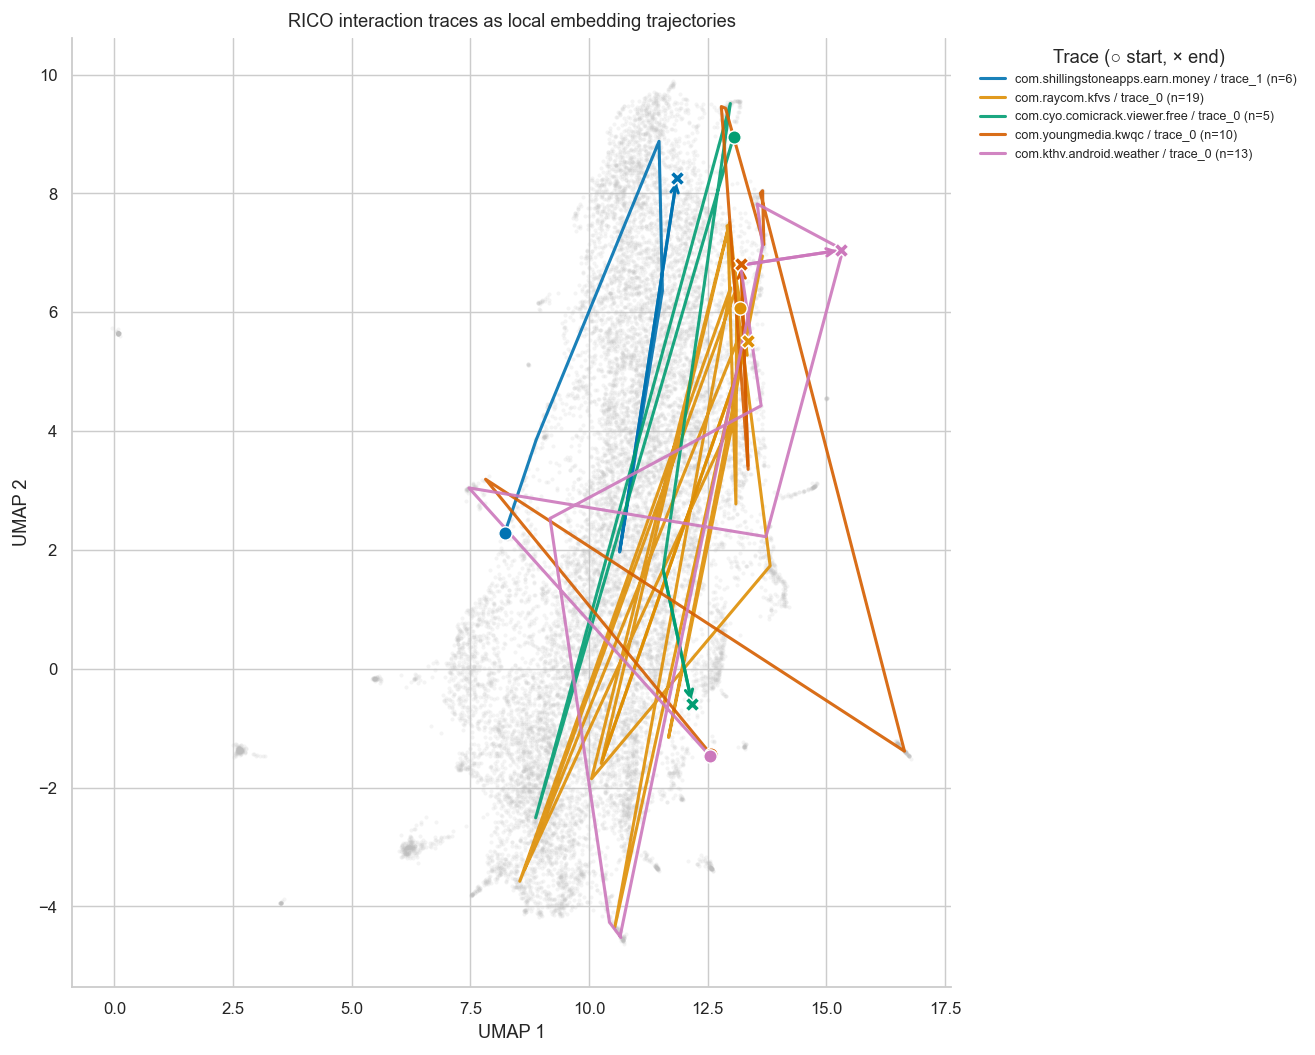

In [4]:
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
ax.scatter(coords[:, 0], coords[:, 1], s=5, color="#bdbdbd", alpha=0.16, linewidths=0, rasterized=True)
colors = sns.color_palette("colorblind", N_TRACES_TO_PLOT)
for color, row in zip(colors, plot_traces):
    trace_coords = np.stack([coord_by_id[screen_id] for screen_id in row["layout_ids"]])
    label = f"{row['app']} / {row['trace']} (n={len(trace_coords)})"
    ax.plot(trace_coords[:, 0], trace_coords[:, 1], color=color, linewidth=1.7, alpha=0.9, label=label, zorder=3)
    ax.scatter(*trace_coords[0], s=55, marker="o", color=color, edgecolor="white", linewidth=0.8, zorder=4)
    ax.scatter(*trace_coords[-1], s=65, marker="X", color=color, edgecolor="white", linewidth=0.8, zorder=4)
    ax.annotate("", xy=trace_coords[-1], xytext=trace_coords[-2], arrowprops={"arrowstyle": "->", "color": color, "lw": 1.7})
ax.set(title="RICO interaction traces as local embedding trajectories", xlabel="UMAP 1", ylabel="UMAP 2")
ax.legend(title="Trace (○ start, × end)", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
sns.despine(ax=ax)
fig.savefig(OUTPUT_DIR / "interaction_trace_trajectories_umap.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "interaction_trace_trajectories_umap.pdf", bbox_inches="tight")
plt.show()

,count,mean,median,std
pair type,,,,
Consecutive trace screens,5000,0.1022,0.0861,0.0794
Random screens,5000,0.1844,0.1607,0.0933


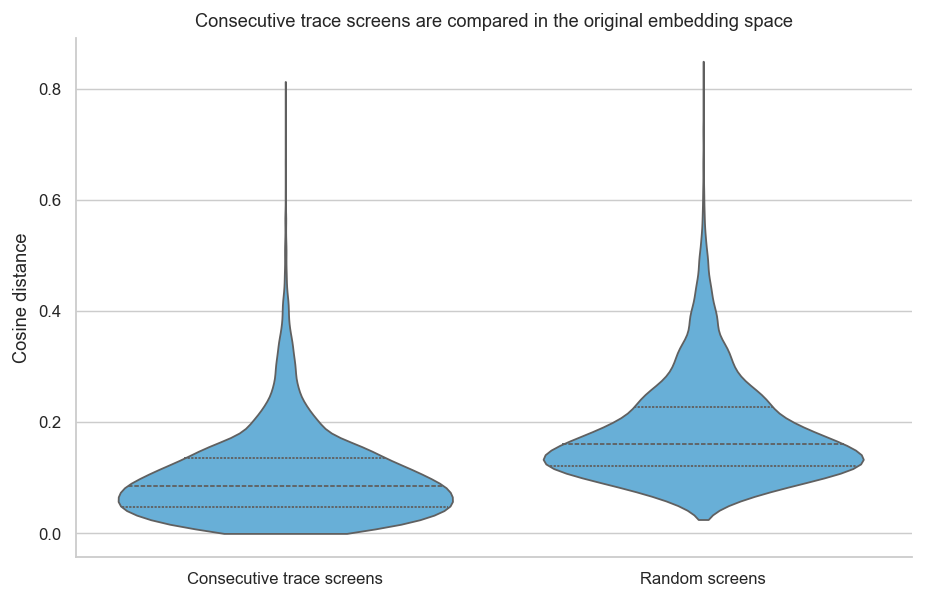

In [5]:
left = np.array([id_to_row[a] for a, _ in transitions])
right = np.array([id_to_row[b] for _, b in transitions])
consecutive_distance = 1 - np.einsum("ij,ij->i", X[left], X[right])
background_rows = np.array([id_to_row[screen_id] for screen_id in background_ids])
random_left = rng.choice(background_rows, size=len(transitions), replace=True)
random_right = rng.choice(background_rows, size=len(transitions), replace=True)
same = random_left == random_right
while same.any():
    random_right[same] = rng.choice(background_rows, size=same.sum(), replace=True)
    same = random_left == random_right
random_distance = 1 - np.einsum("ij,ij->i", X[random_left], X[random_right])
distance_frame = pd.DataFrame({"cosine distance": np.r_[consecutive_distance, random_distance], "pair type": ["Consecutive trace screens"] * len(consecutive_distance) + ["Random screens"] * len(random_distance)})
summary = distance_frame.groupby("pair type")["cosine distance"].agg(["count", "mean", "median", "std"])
display(summary.style.format({"mean": "{:.4f}", "median": "{:.4f}", "std": "{:.4f}"}))
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
sns.violinplot(data=distance_frame, x="pair type", y="cosine distance", inner="quartile", cut=0, color="#56B4E9", ax=ax)
ax.set(title="Consecutive trace screens are compared in the original embedding space", xlabel="", ylabel="Cosine distance")
sns.despine(ax=ax)
fig.savefig(OUTPUT_DIR / "trace_vs_random_cosine_distance.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "trace_vs_random_cosine_distance.pdf", bbox_inches="tight")
plt.show()
summary.to_csv(OUTPUT_DIR / "trace_vs_random_cosine_distance.csv")